# Otimização do Random Forest – Passos 1 e 2: qual abordagem?

**Objetivo da nova fase:** chegar no maior retorno por capital investido com o Random Forest. As regras de tempo
não mudam: re-treino trimestral com janela deslizante, **todas as escolhas na validação (01–12/2024)**, teste
(01/2025–03/2026) rodado uma vez no final.

Este notebook **não toca no teste**. Ele compara três formas de usar a floresta no mesmo cenário da rodada anterior
(1 min × 12 meses, `rf_d4_f2`: 100 árvores, profundidade 4, folha mínima de 2% do treino):

| Abordagem | O que a floresta aprende | Sinal usado para operar |
|---|---|---|
| **A. Regressor** (baseline) | O retorno do próximo candle (erro quadrático) | Retorno previsto |
| **B. Classificador 3 classes** | Sobe > 5 pts / desce > 5 pts / neutro | P(sobe) − P(desce) |
| **C. Classificador + magnitude** | As mesmas árvores de B; em cada folha guardamos também os pontos que os candles de treino andaram | Valor esperado da operação (pts) |

**Ponto importante sobre C:** o valor esperado de comprar é
`P(sobe)·subida média + P(neutro)·média dos neutros − P(desce)·|queda média|`, que é exatamente a **média dos pontos
dos candles de treino da folha**. Ou seja, C é um "regressor" cujas árvores foram construídas pela pureza das
classes, e não pelo erro quadrático. A diferença em relação a A está em **como as divisões são escolhidas**: o erro
quadrático é dominado pelos poucos candles de movimento enorme; as classes dão o mesmo peso a todo movimento que
paga o custo. A vantagem extra de C é ter um limiar natural, em pontos: **só opera se o valor esperado for maior
que o custo**.

**Regras testadas** (nas previsões salvas, sem retreinar):
- `por_minuto`: uma operação por candle, entra no fechamento de t e sai no de t+1.
- `segurar`: entra quando o sinal passa o limiar e mantém até o sinal passar o limiar do lado oposto; zera no fim do pregão.
- Limiar como quantil de |sinal| na validação: 0, 50, 75, 90, 95 e 98%. Em C, também o limiar natural (VE > custo).

**Métrica e critério (passo 0):**
- Custo de 5 pts por operação completa; 1 contrato; 1 ponto = R$ 0,20.
- **Retorno sobre capital** = lucro líquido ÷ (margem + drawdown máximo). Margem por contrato em `MARGEM_R` (**a confirmar**).
- Uma configuração só é candidata se tiver **esperança > 0 com t ≥ 2** e **lucro em pelo menos 3 dos 4 trimestres**
  de 2024. Entre as candidatas, vence o maior retorno sobre capital.
- Se nenhuma configuração passar, a abordagem que segue é a de **melhor sinal** (maior t do ganho bruto, sem custo),
  como na rodada anterior, quando o desempate foi o Theil U.

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))   # notebook em frentes/ml/

sys.path.append(PASTA)
import tt1_comum as t

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
os.makedirs(f"{SAIDA}/previsoes", exist_ok=True)

CANDLE, JANELA = "1min", 12
N_ARVORES, PROF, FOLHA_FRAC, FOLHA_MIN = 100, 4, 0.02, 10      # rf_d4_f2 da rodada anterior
CUSTO = 5.0                                                     # pts por operação completa
CORTE_CLASSE = 5.0                                              # sobe/desce = movimento maior que o custo
QUANTIS = [0.0, 0.5, 0.75, 0.9, 0.95, 0.98]
T_MIN, TRIM_MIN = 2.0, 3                                        # t ≥ 2 e lucro em ≥ 3 de 4 trimestres
MARGEM_R = 150.0                                                # margem por contrato WIN em R$ — A CONFIRMAR
FEATS = t.features()["COMPLETO"]

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
df, s = t.montar_base(win, wdo, CANDLE)
df["mov_pts"] = df.close_prox - df.close                          # pontos do candle t+1 (mesma conta da simulação)
df["classe"] = np.where(df.mov_pts > CORTE_CLASSE, 1, np.where(df.mov_pts < -CORTE_CLASSE, -1, 0))
val = df[(df.index >= t.VALIDACAO[0]) & (df.index < t.VALIDACAO[1])]
print(f"Base {CANDLE}: {len(df):,} candles | validação 2024: {len(val):,}")
print("Classes na validação:", val.classe.value_counts(normalize=True).sort_index().round(3).to_dict())

Base 1min: 686,208 candles | validação 2024: 141,216
Classes na validação: {-1: 0.4, 0: 0.2, 1: 0.4}


## Os três modelos

Os três usam a mesma floresta da rodada anterior (100 árvores, profundidade 4, `max_features = 0,5`, folha mínima
= 2% das linhas de treino). B e C são **a mesma floresta** (treinada uma vez); só muda o sinal usado.

Para B e C, as estatísticas de cada folha (proporção de cada classe e média de pontos) são calculadas com **todas** as
linhas de treino que caem na folha, não só com a amostra *bootstrap* da árvore. Assim as probabilidades e o valor
esperado vêm da mesma conta.

In [2]:
def min_leaf(n):
    return max(FOLHA_MIN, int(FOLHA_FRAC * n))

def walk_forward_prob(df, inicio, fim, janela_meses, embargo=1):
    """Walk-forward trimestral (mesma lógica de tt1_comum.walk_forward), devolvendo para cada candle:
    retorno previsto pelo regressor (A), P(sobe)/P(neutro)/P(desce) e valor esperado em pts (B e C)."""
    cortes = sorted(set(list(pd.date_range(inicio, fim, freq=t.RETREINO)) + [pd.Timestamp(fim)]))
    blocos = []
    for ini, fim_b in zip(cortes[:-1], cortes[1:]):
        tr = df[(df.index >= ini - pd.DateOffset(months=janela_meses)) & (df.index < ini)].iloc[:-embargo]
        te = df[(df.index >= ini) & (df.index < fim_b)]
        if te.empty or tr.empty:
            continue
        ml = min_leaf(len(tr))
        Xtr, Xte = tr[FEATS].values, te[FEATS].values
        # A: regressor (baseline)
        reg = RandomForestRegressor(n_estimators=N_ARVORES, max_depth=PROF, max_features=0.5, min_samples_leaf=ml,
                                    n_jobs=-1, random_state=42).fit(Xtr, tr.alvo.values)
        # B/C: classificador de 3 classes + estatísticas das folhas
        clf = RandomForestClassifier(n_estimators=N_ARVORES, max_depth=PROF, max_features=0.5, min_samples_leaf=ml,
                                     n_jobs=-1, random_state=42).fit(Xtr, tr.classe.values)
        cls, mov = tr.classe.values, tr.mov_pts.values
        p_up = np.zeros(len(te)); p_dn = np.zeros(len(te)); ev = np.zeros(len(te))
        for est in clf.estimators_:
            f_tr, f_te = est.apply(Xtr), est.apply(Xte)
            k = est.tree_.node_count
            n = np.bincount(f_tr, minlength=k).astype(float)
            n_safe = np.where(n > 0, n, 1)
            p_up += (np.bincount(f_tr, weights=(cls == 1), minlength=k) / n_safe)[f_te]
            p_dn += (np.bincount(f_tr, weights=(cls == -1), minlength=k) / n_safe)[f_te]
            ev += (np.bincount(f_tr, weights=mov, minlength=k) / n_safe)[f_te]
        nt = len(clf.estimators_)
        blocos.append(pd.DataFrame({
            "y_true": te.alvo, "pred_reg": reg.predict(Xte),
            "p_sobe": p_up / nt, "p_desce": p_dn / nt, "ve_pts": ev / nt,
            "mov_pts": te.mov_pts, "close": te.close, "high_prox": te.high_prox, "low_prox": te.low_prox,
            "close_prox": te.close_prox, "volat": te.volat}, index=te.index))
        print(f"  {ini.date()}: treino {len(tr):,} linhas (folha mín. {ml}) | prevê {len(te):,}")
    out = pd.concat(blocos)
    out["dif_prob"] = out.p_sobe - out.p_desce
    return out

arq = f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_abordagens_val.csv"
t0 = time.time()
PREV = walk_forward_prob(df, *t.VALIDACAO, janela_meses=JANELA)
PREV.to_csv(arq)
print(f"{len(PREV):,} previsões em {time.time() - t0:.0f}s")

SINAIS = {"A_regressor": "pred_reg", "B_classif_dif_prob": "dif_prob", "C_classif_valor_esperado": "ve_pts"}
PREV[["pred_reg", "p_sobe", "p_desce", "dif_prob", "ve_pts"]].describe(percentiles=[.02, .1, .5, .9, .98]).round(4)

  2024-01-01: treino 84,568 linhas (folha mín. 1691) | prevê 34,148


  2024-04-01: treino 83,891 linhas (folha mín. 1677) | prevê 35,509


  2024-07-01: treino 96,974 linhas (folha mín. 1939) | prevê 37,163


  2024-10-01: treino 134,137 linhas (folha mín. 2682) | prevê 34,396


141,216 previsões em 33s


,pred_reg,p_sobe,p_desce,dif_prob,ve_pts
count,141216.0000,141216.0000,141216.0000,141216.0000,141216.0000
mean,0.0001,0.4039,0.3998,0.0041,0.1394
std,0.0006,0.0281,0.0305,0.0147,0.4463
min,-0.0038,0.3143,0.2889,-0.0437,-1.4411
2%,-0.0011,0.3333,0.3170,-0.0220,-0.6010
10%,-0.0004,0.3680,0.3634,-0.0110,-0.2529
50%,0.0001,0.4035,0.3993,0.0013,0.0485
90%,0.0005,0.4384,0.4396,0.0233,0.6134
98%,0.0023,0.4506,0.4468,0.0454,1.6552
max,0.0042,0.4688,0.4604,0.0662,2.5967


## Qualidade do sinal antes de operar

Antes das regras, uma medida sem custo e sem limiar: a **correlação de Spearman** entre o sinal e os pontos do
candle seguinte, e o **ganho bruto** (custo zero) de operar todo minuto na direção do sinal. Se uma abordagem não
ordena melhor os candles, nenhuma regra vai salvá-la.

In [3]:
def estat(x):
    x = pd.Series(x)
    if len(x) < 30:
        return dict(n_ops=len(x), esperanca_pts=np.nan, ep_pts=np.nan, t_stat=np.nan)
    ep = x.std() / np.sqrt(len(x))
    return dict(n_ops=len(x), esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep)

linhas = []
for nome, col in SINAIS.items():
    bruto = np.sign(PREV[col]) * PREV.mov_pts
    linhas.append(dict(abordagem=nome, spearman=PREV[col].corr(PREV.mov_pts, method="spearman"),
                       acc_dir=(np.sign(PREV[col]) == np.sign(PREV.mov_pts))[PREV.mov_pts != 0].mean(),
                       **{f"bruto_{k}": v for k, v in estat(bruto[PREV[col] != 0]).items()}))
qualidade = pd.DataFrame(linhas)
qualidade.to_csv(f"{SAIDA}/abordagens_qualidade_val.csv", index=False)
qualidade.round(4)

,abordagem,spearman,acc_dir,bruto_n_ops,bruto_esperanca_pts,bruto_ep_pts,bruto_t_stat
0,A_regressor,0.0131,0.5093,141216,0.2895,0.1121,2.5822
1,B_classif_dif_prob,0.0193,0.5117,141216,0.4007,0.1121,3.5747
2,C_classif_valor_esperado,0.0160,0.5075,141216,0.2464,0.1121,2.1981


## Regras de operação e métrica de retorno

- `por_minuto`: usa `tt1_comum.simular` (sem TP/SL nesta etapa).
- `segurar`: mesma lógica da `variante_segurar_posicao.ipynb`.
- Para cada configuração: esperança, t, lucro por trimestre, drawdown máximo e retorno sobre capital.
- Referência aleatória: mesmas operações e durações, direção sorteada.

In [4]:
def posicoes(sinal, dias, limiar):
    pos, p = np.zeros(len(sinal)), 0
    for i in range(len(sinal)):
        if i == 0 or dias[i] != dias[i - 1]:
            p = 0
        if sinal[i] > limiar:
            p = 1
        elif sinal[i] < -limiar:
            p = -1
        pos[i] = p
    return pos

def ops_segurar(prev, col, limiar, custo):
    dias = prev.index.date
    pos = posicoes(prev[col].values, dias, limiar)
    nova = (pos != np.roll(pos, 1)) | (dias != np.roll(dias, 1))
    nova[0] = True
    d = pd.DataFrame({"op": np.cumsum(nova), "lado": pos, "pts": pos * prev.mov_pts.values, "inicio": prev.index})
    d = d[d.lado != 0]
    o = d.groupby("op").agg(lado=("lado", "first"), bruto=("pts", "sum"), minutos=("pts", "size"),
                            inicio=("inicio", "first"))
    o["pontos"] = o.bruto - custo
    return o.set_index("inicio")

def ops_por_minuto(prev, col, limiar, custo):
    o = t.simular(prev.assign(y_pred=prev[col]), limiar, None, None, custo)
    o = o[o.lado != 0].copy()
    o["bruto"], o["minutos"] = o.pontos + custo, 1
    return o

def aleatorio(o, custo, seed=42):
    rng = np.random.default_rng(seed)
    return o.assign(pontos=o.bruto * rng.choice([-1, 1], size=len(o)) - custo)

def avaliar(o, n_dias):
    x = o.pontos
    r = estat(x)
    if len(x) == 0:
        return r
    acum = x.cumsum() * t.PONTO_WIN
    dd = float((acum.cummax().clip(lower=0) - acum).max())
    trim = x.groupby(x.index.to_period("Q")).sum()
    lucro = x.sum() * t.PONTO_WIN
    g, p = x[x > 0], x[x < 0]
    return dict(**r, ops_por_dia=len(x) / n_dias, minutos_medios=o.minutos.mean(), taxa_acerto=(x > 0).mean(),
                payoff=g.mean() / -p.mean() if len(g) and len(p) else np.nan,
                fator_lucro=g.sum() / -p.sum() if len(p) else np.inf,
                bruto_pts=o.bruto.mean(), lucro_R=lucro, drawdown_R=dd,
                retorno_capital=lucro / (MARGEM_R + dd),
                trimestres_positivos=int((trim > 0).sum()), n_trimestres=len(trim))

n_dias = len(set(PREV.index.date))
linhas = []
for nome, col in SINAIS.items():
    lims = {f"q{q:.0%}": t.limiar_por_quantil(PREV.assign(y_pred=PREV[col]), q) for q in QUANTIS}
    if col == "ve_pts":
        lims["VE>custo"] = CUSTO
    for rot, lim in lims.items():
        for regra, f in [("por_minuto", ops_por_minuto), ("segurar", ops_segurar)]:
            o = f(PREV, col, lim, CUSTO)
            linhas.append(dict(abordagem=nome, regra=regra, limiar=rot, limiar_valor=lim, serie="modelo", **avaliar(o, n_dias)))
            if len(o):
                linhas.append(dict(abordagem=nome, regra=regra, limiar=rot, limiar_valor=lim, serie="aleatorio",
                                   **avaliar(aleatorio(o, CUSTO), n_dias)))
res = pd.DataFrame(linhas)
res["candidata"] = ((res.serie == "modelo") & (res.esperanca_pts > 0) & (res.t_stat >= T_MIN)
                    & (res.trimestres_positivos >= TRIM_MIN))
res.to_csv(f"{SAIDA}/abordagens_regras_val.csv", index=False)

cols = ["abordagem", "regra", "limiar", "n_ops", "ops_por_dia", "minutos_medios", "taxa_acerto", "bruto_pts",
        "esperanca_pts", "t_stat", "lucro_R", "drawdown_R", "retorno_capital", "trimestres_positivos", "candidata"]
mod = res[res.serie == "modelo"].sort_values("esperanca_pts", ascending=False)
mod[cols].round(3)

,abordagem,regra,limiar,n_ops,ops_por_dia,minutos_medios,taxa_acerto,bruto_pts,esperanca_pts,t_stat,lucro_R,drawdown_R,retorno_capital,trimestres_positivos,candidata
62,C_classif_valor_esperado,segurar,q90%,1888,7.522,66.616,0.597,4.801,-0.199,-0.026,-75.0,2034.0,-0.034,2.0,False
66,C_classif_valor_esperado,segurar,q95%,1112,4.430,98.458,0.600,4.362,-0.638,-0.055,-142.0,2334.0,-0.057,2.0,False
58,C_classif_valor_esperado,segurar,q75%,5421,21.598,23.610,0.590,3.869,-1.131,-0.415,-1226.0,2098.0,-0.545,2.0,False
18,A_regressor,segurar,q95%,2107,8.394,65.980,0.598,3.479,-1.521,-0.206,-641.0,2155.0,-0.278,2.0,False
34,B_classif_dif_prob,segurar,q75%,9639,38.402,12.759,0.581,3.127,-1.873,-1.295,-3610.0,4865.0,-0.720,2.0,False
14,A_regressor,segurar,q90%,6364,25.355,22.130,0.576,2.498,-2.502,-1.027,-3185.0,4789.0,-0.645,1.0,False
44,B_classif_dif_prob,por_minuto,q98%,2825,11.255,1.000,0.466,2.496,-2.504,-2.492,-1415.0,1692.0,-0.768,0.0,False
64,C_classif_valor_esperado,por_minuto,q95%,7061,28.131,1.000,0.463,2.466,-2.534,-3.773,-3578.0,3632.0,-0.946,0.0,False
10,A_regressor,segurar,q75%,13626,54.287,10.353,0.562,2.461,-2.539,-2.247,-6919.0,8437.0,-0.806,0.0,False
30,B_classif_dif_prob,segurar,q50%,24428,97.323,5.770,0.567,2.384,-2.616,-3.989,-12781.0,13935.0,-0.907,1.0,False


## Valor do modelo: modelo × aleatório nas mesmas operações

Diferença de esperança entre o modelo e a direção sorteada, nas mesmas operações. Mostra quanto do resultado vem da
previsão (e não da regra ou do mercado).

In [5]:
piv = res.pivot_table(index=["abordagem", "regra", "limiar"], columns="serie", values="esperanca_pts")
piv["valor_do_modelo"] = piv.modelo - piv.aleatorio
piv.round(2)

serie                                       aleatorio  modelo  valor_do_modelo
abordagem                regra      limiar                                    
A_regressor              por_minuto q0%         -4.84   -4.71             0.13
                                    q50%        -5.12   -4.66             0.46
                                    q75%        -5.13   -4.39             0.74
                                    q90%        -4.80   -3.55             1.25
                                    q95%        -4.38   -3.00             1.39
                                    q98%        -6.13   -3.40             2.73
                         segurar    q0%         -4.37   -4.22             0.15
                                    q50%        -4.75   -3.52             1.23
                                    q75%        -5.31   -2.54             2.78
                                    q90%        -7.29   -2.50             4.79
                                    q95%        -6.76   -1.52             5.24
                                    q98%        -0.94  -25.40           -24.46
B_classif_dif_prob       por_minuto q0%         -4.99   -4.60             0.39
                                    q50%        -5.24   -4.51             0.73
                                    q75%        -4.94   -4.43             0.50
                                    q90%        -5.08   -4.31             0.78
                                    q95%        -5.49   -3.64             1.84
                                    q98%        -5.66   -2.50             3.15
                         segurar    q0%         -5.12   -3.97             1.15
                                    q50%        -5.62   -2.62             3.01
                                    q75%        -3.53   -1.87             1.65
                                    q90%        -1.88   -9.28            -7.40
                                    q95%        -2.18  -10.26            -8.08
                                    q98%       -19.26  -24.87            -5.61
C_classif_valor_esperado por_minuto q0%         -4.91   -4.75             0.16
                                    q50%        -5.07   -4.56             0.50
                                    q75%        -5.26   -4.50             0.76
                                    q90%        -5.02   -3.90             1.13
                                    q95%        -4.10   -2.53             1.57
                                    q98%        -3.23   -2.62             0.61
                         segurar    q0%         -5.66   -4.21             1.44
                                    q50%        -4.89   -3.13             1.75
                                    q75%        -0.99   -1.13            -0.14
                                    q90%       -18.37   -0.20            18.17
                                    q95%        -9.06   -0.64             8.42
                                    q98%       -53.39  -39.74            13.65

## Decisão do passo 2

In [6]:
cand = res[res.candidata].sort_values("retorno_capital", ascending=False)
if len(cand):
    v = cand.iloc[0]
    CRITERIO = "maior retorno sobre capital entre as candidatas (esperança > 0, t ≥ 2, ≥ 3 trimestres positivos)"
else:
    # nenhuma candidata: mesma lógica da rodada anterior (sem lucro significativo, decide a qualidade da previsão).
    # Aqui a qualidade é o t do ganho bruto (custo 0, todo minuto, direção do sinal), que não depende de limiar
    # nem de regra. A esperança com custo das regras 'segurar' com limiar alto é dominada por ruído (t ≈ 0).
    melhor = qualidade.sort_values("bruto_t_stat", ascending=False).iloc[0].abordagem
    seg = res[(res.serie == "modelo") & (res.abordagem == melhor)]
    v = seg.sort_values("esperanca_pts", ascending=False).iloc[0]
    CRITERIO = ("nenhuma candidata: abordagem escolhida pelo maior t do ganho bruto (qualidade do sinal); "
                "linha mostrada = sua melhor regra, só como diagnóstico")
print("Critério:", CRITERIO)
print(f"Vencedora: {v.abordagem} | regra {v.regra} | limiar {v.limiar} | esperança {v.esperanca_pts:.2f} pts/op "
      f"(t = {v.t_stat:.2f}) | lucro R$ {v.lucro_R:,.0f} | DD R$ {v.drawdown_R:,.0f} | "
      f"retorno/capital {v.retorno_capital:.2f} | trimestres positivos {v.trimestres_positivos}/{v.n_trimestres}")
print(f"Candidatas: {len(cand)} de {int((res.serie == 'modelo').sum())} configurações")

decisao = dict(passo="2 - abordagem", candle=CANDLE, janela_meses=JANELA, custo_pts=CUSTO, margem_R=MARGEM_R,
               criterio=CRITERIO, n_candidatas=int(len(cand)), abordagem=v.abordagem, regra=v.regra, limiar=v.limiar,
               limiar_valor=float(v.limiar_valor), esperanca_pts=float(v.esperanca_pts), t_stat=float(v.t_stat),
               lucro_R=float(v.lucro_R), retorno_capital=float(v.retorno_capital),
               trimestres_positivos=int(v.trimestres_positivos))
json.dump(decisao, open(f"{SAIDA}/decisao_passo2.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

Critério: nenhuma candidata: abordagem escolhida pelo maior t do ganho bruto (qualidade do sinal); linha mostrada = sua melhor regra, só como diagnóstico
Vencedora: B_classif_dif_prob | regra segurar | limiar q75% | esperança -1.87 pts/op (t = -1.30) | lucro R$ -3,610 | DD R$ 4,865 | retorno/capital -0.72 | trimestres positivos 2.0/4.0
Candidatas: 0 de 38 configurações


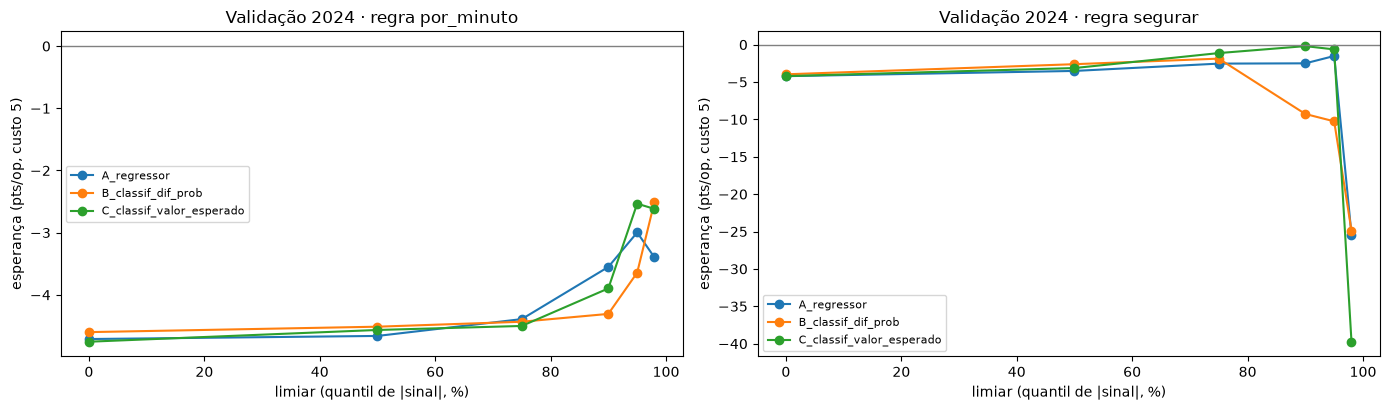

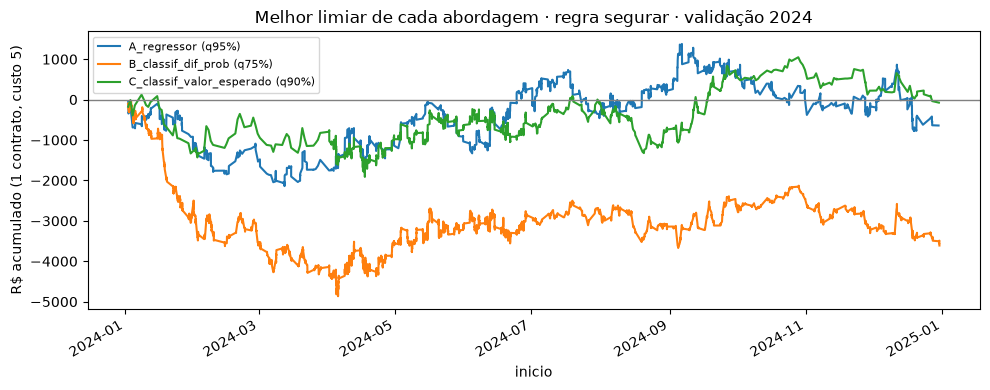

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, regra in zip(axes, ["por_minuto", "segurar"]):
    for nome, col in SINAIS.items():
        r = res[(res.serie == "modelo") & (res.regra == regra) & (res.abordagem == nome) & res.limiar.str.startswith("q")]
        ax.plot([float(l[1:-1]) for l in r.limiar], r.esperanca_pts, "o-", label=nome)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xlabel("limiar (quantil de |sinal|, %)"); ax.set_ylabel("esperança (pts/op, custo 5)")
    ax.set_title(f"Validação 2024 · regra {regra}"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/abordagens_esperanca_val.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for nome, col in SINAIS.items():
    r = res[(res.serie == "modelo") & (res.regra == "segurar") & (res.abordagem == nome)]
    best = r.sort_values("esperanca_pts", ascending=False).iloc[0]
    o = ops_segurar(PREV, col, best.limiar_valor, CUSTO)
    (o.pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, label=f"{nome} ({best.limiar})")
ax.axhline(0, color="gray", lw=1); ax.set_ylabel("R$ acumulado (1 contrato, custo 5)")
ax.set_title("Melhor limiar de cada abordagem · regra segurar · validação 2024"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/abordagens_curvas_val.png", dpi=150); plt.show()